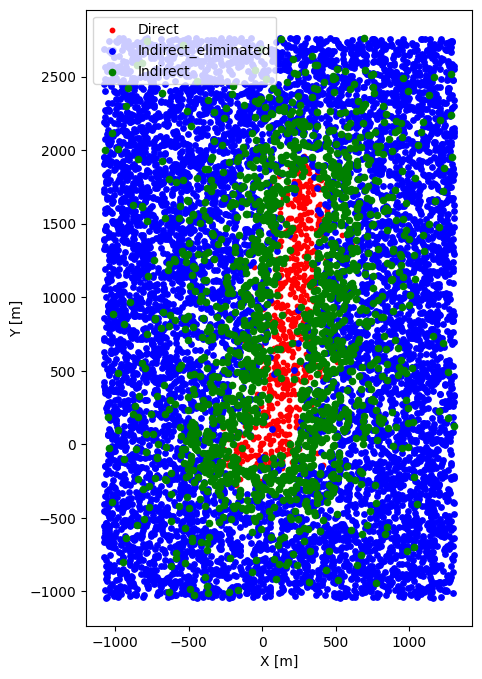

In [1]:
import matplotlib.pyplot as plt
from plot_lib.plotylk import plot_lightnings, plot_lines, plot_nodes
from plot_lib.plot_stat import compute_voltage_bins, plot_exceedance_across_nodes, plot_log_fail
import pandas as pd

lig_stat=pd.read_csv("J-JB_light.csv",sep=";")
fig, ax = plt.subplots(figsize=(10, 8))

#plot_lines(net.df_lines, coord_type="car", ax=ax)
#plot_nodes(net.df_nodes, coord_type="car", ax=ax)
plot_lightnings(lig_stat,
                coord_type="car",
                mode="categorical",
                ax=ax)

plt.show()

In [2]:
lig_stat['direct_strike'].value_counts()

direct_strike
0    9371
1     629
Name: count, dtype: int64

In [3]:
import pandas as pd

df_voltage = pd.read_csv("J-JB_max.csv")
#print(df_voltage.head())

voltage_cols = df_voltage.columns
df_voltage[voltage_cols] = df_voltage[voltage_cols]/1000. 
df_circuit = pd.DataFrame({voltage_cols[-1]: df_voltage[voltage_cols[-1]]})
#df_voltage.drop(columns=["Case"], inplace=True)
df_voltage.drop(columns=[voltage_cols[-1]], inplace=True, errors="ignore")
#print(df_voltage.max())


In [4]:
bins_circuit = compute_voltage_bins(
    df_circuit,
    vmin=50,
    vmax=300,
    bin_size=1,
    exceed_value=100
)
bins_dict = compute_voltage_bins(
    df_voltage,
    vmin=50,
    vmax=300,
    bin_size=1,
    exceed_value=None
)
bins_circuit

{'max':      bin_min  bin_max  count  exceed_count
 0         50       51      0          1655
 1         51       52      0          1655
 2         52       53      0          1655
 3         53       54      0          1655
 4         54       55      0          1655
 ..       ...      ...    ...           ...
 245      295      296      1            12
 246      296      297      0            11
 247      297      298      0            11
 248      298      299      0            11
 249      299      300      1            11
 
 [250 rows x 4 columns]}

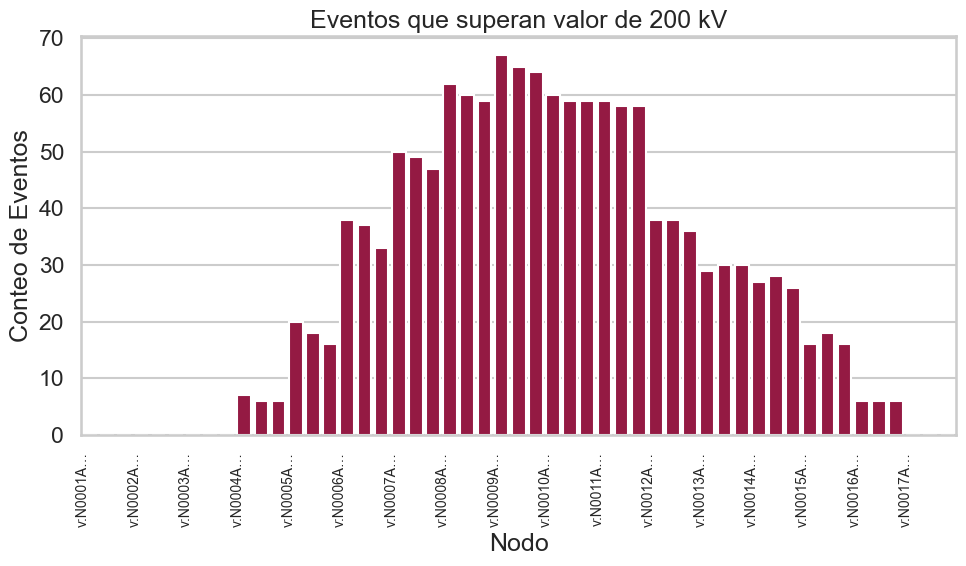

In [5]:
result_df = plot_exceedance_across_nodes(
    df_voltage,
    threshold=200
)

Exceedance at Vcfo (200 kV): 4.500000e-03


(<Figure size 900x600 with 1 Axes>,
 <Axes: title={'center': 'Probabilidad de falla vs CFO'}, xlabel='CFO (kV)', ylabel='Probailidad'>)

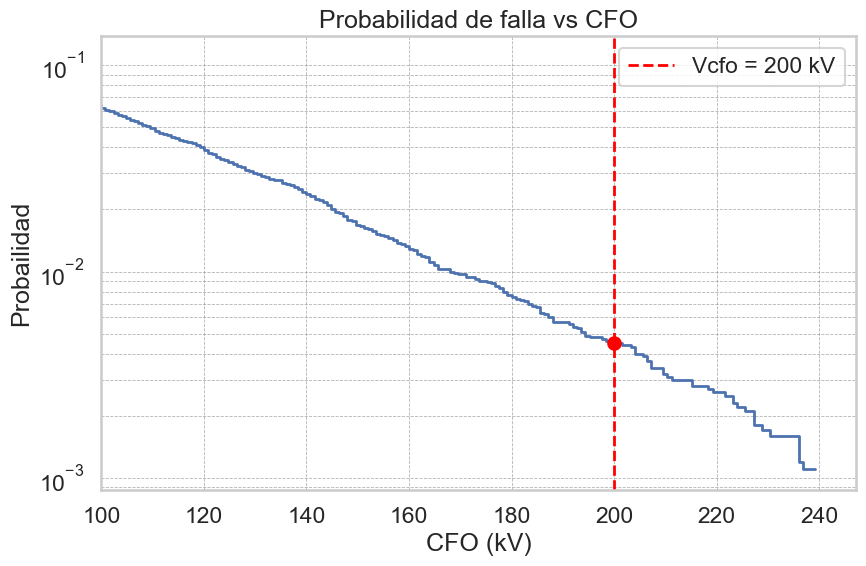

In [6]:
bins_circuit.keys()

plot_log_fail(bins_circuit,nmax=10000,CFO_factor=1.25)